# **Eigenfaces**

In this project, we aimed to integrate different topics covered in the course, including **Principal Component Analysis (PCA)** and **Singular Value Decomposition (SVD)**, and apply them to a **real-world problem** such as a **facial recognition** algorithm based on the Eigenfaces approach.

In [ ]:
import numpy as np
from PIL import Image
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import fetch_olivetti_faces
import matplotlib.pyplot as plt

# Olivetti Dataset
We consider the Olivetti Faces dataset, which consists of grayscale facial images of 40 distinct subjects, with 10 images available for each subject.
For the training phase, **9 images** per subject are selected, while the remaining image is reserved for **testing**.
The objective of this study is to correctly identify the subject associated with a given test image, while ensuring a **computationally efficient recognition procedure**.

The methodology followed a progressive approach:
1)  A naive solution was implemented in which the **entire dataset was stored** for recognition.
2) To improve computational efficiency, we experimented with representing each subject using the **average of their images**, thus storing only one image per subject. Although this approach significantly reduced memory usage, it led to a decrease in recognition performance.
3) Finally, a **change of basis** was applied using PCA, selecting the most representative eigenvectors to form a reduced-dimensional subspace. This approach allowed us to achieve a trade-off between recognition accuracy and computational cost.

To perform the basis change we did not use the libraries but **implemented our own SVD method** which allows us to obtain the eigenvectors and eigenvalues ​​of the covariance matrix without explicitly calculating it.



In [ ]:
people=np.load("olivetti_faces.npy")
people=people.reshape((people.shape[0],people.shape[1]*people.shape[2]))
target=np.load("olivetti_faces_target.npy")
df=pd.DataFrame(people)
df['target']=target
X_test=[]
y_test=[]
for i in range(0,400,10):
  X_test.append(df.iloc[i,:-1])
  y_test.append(df.iloc[i,-1])
X_test=pd.DataFrame(X_test)
indici=X_test.index
X_train=df.drop(indici,axis=0)
X_train=pd.DataFrame(X_train).drop(columns='target')
y_train=df.drop(indici,axis=0)['target']

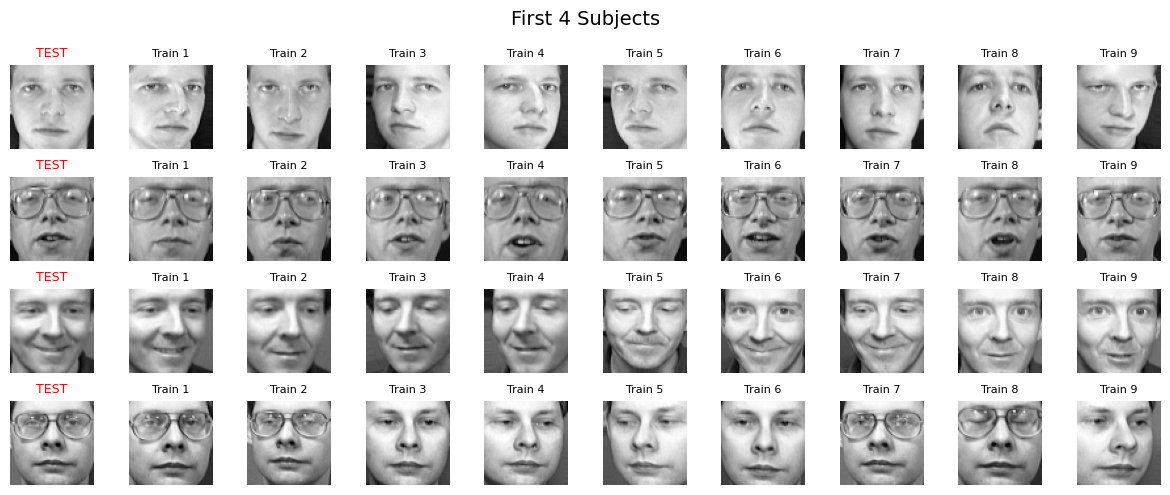

In [ ]:
fig, axes = plt.subplots(4, 10, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    eigenface = np.array(df.iloc[i, :-1]).reshape(64, 64)
    ax.imshow(eigenface, cmap='gray')
    row = i // 10
    col = i % 10
    if col == 0:
        ax.set_title("TEST", fontsize=9, color='red')
        for spine in ax.spines.values():
            spine.set_edgecolor('red')
            spine.set_linewidth(2)
    else:
        ax.set_title(f"Train {col}", fontsize=8)
    ax.axis('off')
plt.suptitle("First 4 Subjects", fontsize=14)
plt.tight_layout()
plt.show()

___

# **1) Naive method**

A straightforward baseline approach consists in storing all the training images and applying a **k-nearest neighbors** (KNN) classifier directly in the **original image space**. For each test image, the Euclidean distance is computed with respect to all 360 training images (corresponding to 40 subjects with 9 images per subject), and the label of the closest match is selected.

Each image has a spatial resolution of 64x64 pixels, resulting in a **feature vector of 4096 dimensions** for each sample. Consequently, for every test image, the computational cost of the classification step scales linearly with both the number of training samples and the dimensionality of the feature space, i.e.,
**O(N⋅d), where N=360=40*9 and d=4096**. This high-dimensional representation leads to increased computational cost and memory usage, making the naive approach inefficient and poorly scalable.

With this method only a **single test image is not correctly classified**, which is expected since the training set has never seen the images used for testing. Therefore, some misclassifications may occur.

In [ ]:
kn=KNeighborsClassifier(n_neighbors=1)
kn.fit(X_train,y_train)
y_pred=kn.predict(X_test)
acc=np.array([y_pred==y_test]).sum()/len(y_test)
print('Accuracy: ', acc)
print('Number of wrong associations: ', np.array([y_pred!=y_test]).sum())

Accuracy:  0.975
Number of wrong associations:  1


In [ ]:
y_pred

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 25, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
       34, 35, 36, 37, 38, 39], dtype=int32)

Image 22 was predicted as 25

___

# **2) Mean-based method**

The second approach considered is the mean-based method. This technique consists of **averaging all 9 training images for each subject pixel-wise**, thereby creating a final dataset with 40 rows (one per subject) and 4096 columns (corresponding to the average pixel values). By doing so, the computational cost is substantially reduced, as the **distance must now be computed against only 40 images instead of 360.**

However, this simplification comes at the expense of accuracy. In the naive approach, only a single test image was misclassified, whereas using the mean-based method, **4 out of 40 test images are incorrectly classified**, indicating a significant drop in performance.



In [ ]:
lista_persone=[]
for i in range(0, 360, 9):
  lista_persone.append((X_train.iloc[i:i+9,:]))
lista_medie=[]
for persona in lista_persone:
    df_persona=pd.DataFrame(persona)
    media_persona=df_persona.mean(axis=0)
    lista_medie.append(media_persona)
df_medie=pd.DataFrame(lista_medie)


In [ ]:
kn=KNeighborsClassifier(n_neighbors=1)
kn.fit(df_medie,range(40))
y_pred=kn.predict(X_test)
acc=np.array([y_pred==y_test]).sum()/len(y_test)
print('Accuracy: ', acc)
print('Number of wrong associations: ', np.array([y_pred!=y_test]).sum())

Accuracy:  0.9
Number of wrong associations:  4


In [ ]:
y_pred

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 29, 21, 22, 23, 24, 25, 26, 27, 28, 29, 20, 31, 32, 33,
       34, 35, 36, 39, 38, 11])

Image 20 was predicted as 29

Image 30 was predicted as 20

Image 37 was predicted as 39

Image 39 was predicted as 11

___

# **3) PCA-based method**

The final method considered is Principal Component Analysis (PCA), implemented through Singular Value Decomposition (SVD) to **compute the eigenvalues and eigenvectors of the data covariance matrix**. By applying a change of basis, the **original features**(corresponding to individual **pixel intensities**) are transformed into a **new set of features known as eigenfaces**. These eigenfaces represent the principal modes of variation across the facial images and provide a more compact and informative representation of the data. As a result, a significantly **smaller number of features is sufficient** to effectively perform face matching and classification. Moreover, this dimensionality reduction leads to a substantial decrease in computational cost during the classification phase, as **distance computations are performed in a low-dimensional subspace** rather than in the original high-dimensional pixel space

# SVD implementation
We implemented our own SVD algorithm instead of using the built-in PCA or SVD functions in NumPy.

The main idea is that, by computing the matrices $U$, $\Sigma$, and $V^\top$ of a data matrix $S$ (representing a set of face images), we can directly obtain:

- The eigenvectors of the covariance matrix:
$$
\text{Cov}(S) = \frac{S^\top S}{N-1},
$$
- The eigenvalues of the covariance matrix as:
$$
\lambda_i = \frac{\sigma_i^2}{N-1}.
$$

Since our implementation is optimized for matrices with more rows than columns, we transpose $S$. In this case, the columns of $U$ from $A = S^\top$ correspond to the rows of $V^\top$ of the original matrix $S$.





## Fundamental Idea

The fundamental idea behind our SVD implementation is to compute the eigenvectors and eigenvalues of the matrix $A^\top A$. From these, we can obtain:

- The **right singular vectors** of $A$ (from the eigenvectors of $A^\top A$)-> **V**
- The **left singular vectors** of $A$ -> **U**
- The **singular values**, which correspond to the square roots of the eigenvalues of $A^\top A$ -> **$\Sigma$**

To facilitate this computation, we first reduce $A$ to a **bidiagonal matrix** $B$ using our implemented bidiagonalization method. This is advantageous because if
$$
B = W A T,
$$
then
$$
B^\top B = T^\top A^\top W^\top W A T,
$$
which is similar to $A^\top A$, but $B^\top B$ has a **tridiagonal structure**.  
The tridiagonal form makes the computation of eigenvalues significantly simpler and more efficient.

Once the eigenvectors of $B^\top B$ are computed, we can recover the eigenvectors of $A^\top A$ via a change of basis:
$$
Q = T \, [\mathrm{eigenvectors\ of\ } B^\top B],
$$
where $Q$ represents the matrix of **right singular vectors** of $A$ (up to a permutation).

## Summary of SVD Algorithm

1. Reduce $A$ to bidiagonal form $B$ using Householder reflections.
2. Compute eigenvalues and eigenvectors of $B^\top B$ (tridiagonal).
3. Recover the right singular vectors of $A$ via $Q = T \, [\mathrm{eigenvectors\ of\ } B^\top B]$.
4. Project $A$ onto the right singular subspace: $C = AQ$.
5. Perform QR decomposition with column pivoting: $C P = U R$.
6. Obtain $\Sigma = R$ and $V = Q P$.

### **Bidiagonalization**

We first reduce the matrix $A$ to a bidiagonal form $B$ using left and right Householder reflections:

- **Left Householder reflections** eliminate elements below the main diagonal, one column at a time.
- **Right Householder reflections** eliminate elements in a row starting from the second entry after the diagonal.

A Householder vector $v$ is constructed for each column/row to zero out, and the corresponding matrix is
$$
H = I - 2 v v^\top, \quad Hx = (\pm \|x\|, 0, \dots, 0)^\top.
$$

**Efficient Implementation**

To improve computational efficiency, we implement the bidiagonalization using three key strategies:

1. **Use of Householder vectors only:**  
   We never construct the full Householder matrix. Instead, we store only the Householder vector $v$ and apply the transformation directly:
   $$
   WA = A - 2 v (v^\top A), \quad AT = A - 2 (A v) v^\top,
   $$
   reducing the cost from a matrix-matrix product to a matrix-vector product.

2. **Manual insertion of known values:**  
   Since the effect of a Householder transformation is predictable, we can directly set the first element of the transformed vector to $\|x\|$ and the remaining entries to zero. This allows us to avoid unnecessary computations and reduces the effective size of $A$ on which operations are performed.

3. **Efficient handling of the $T$ matrix:**  
   The only matrix required to proceed in the SVD algorithm is $T$, obtained as the product of all right Householder transformations. Instead of explicitly multiplying all Householder matrices at each iteration, we initialize $T$ as an identity matrix of size $n \times n$ and update only the bottom-right submatrix corresponding to the active portion of the transformation.

## **Tridiagonal Eigenvalue Problem**

After bidiagonalization, we obtain matrices $B$ and $T$.

- Compute $B^\top B$, which is tridiagonal.
- Since $B^\top B$ is similar to $A^\top A$, its eigenvalues correspond to those of $A^\top A$.
- The eigenvectors of $A^\top A$ (right singular vectors of $A$) are recovered via a change of basis:
$$
Q = T \, [\mathrm{eigenvectors\ of\ } B^\top B].
$$

We use `numpy.linalg.eigh_tridiagonal`, optimized for tridiagonal matrices, for numerical efficiency.

### **QR Decomposition with Column Pivoting**

Once $Q$ is obtained, we project $A$ onto the right singular subspace:
$$
C = A Q.
$$

Perform a QR decomposition with column pivoting:
$$
C P = U R,
$$
where the pivoting orders the diagonal elements of $R$ from largest to smallest. Here, $R$ corresponds to $\Sigma$ in the SVD.

- $U$ is orthogonal, size $m \times m$
- $\Sigma$ is diagonal (from $R$), size $m \times n$
- $V$ is obtained as $V = Q P$


## **Diagonal Structure of R**

Although QR decomposition gives an upper-triangular matrix, $R$ is in fact diagonal:

$$
A = C Q^\top = (C P) P^\top Q^\top = U R (Q P)^\top
$$

Then,
$$
A^\top A = Q P R^\top U^\top U R P^\top Q^\top = Q P R^\top R P^\top Q^\top
$$

Since $A^\top A = Q D Q^\top$ with $D$ diagonal, it follows that
$$
P R^\top R P^\top = D \implies R^\top R \text{ is diagonal.}
$$

Hence, $R$ itself must be diagonal, confirming that it corresponds to the singular values $\Sigma$.

In [ ]:
from scipy.linalg import eigh_tridiagonal,qr
def householder(x):
    """
    Dato x (vettore a cui voglio applicare H), trovo il vettore v --> H = I - 2vv^T.
    Per ottenere l'effetto desiderato (ovvero Hx=[±||x||, 0, ..., 0] ) devo costruire H, e quindi v, dato x
    """
    v = x.copy().astype(float) #inizializzo v come copia di x -> tutte le componenti dopo la prima sono ok
    #solo controllo
    alpha = np.linalg.norm(x)
    if alpha == 0: #se ha norma 0, restituisco v=x
        return v

    s = np.sign(x[0]) if x[0] != 0 else 1.0 #segno (se zero moltiplico per 1)
    v[0] = s * (abs(x[0]) + alpha)

    v /= np.linalg.norm(v) #normalizzo qui per facilità nella matrice di Householder
    return v

In [ ]:
def bi_diag(A):
    """
    Data la matrice A, la bi-diagonalizzo in modo da poter poi passare a A^H*A --> B^H*B tridiagonale (facile trovare autovalori)
    """
    A = A.copy()
    m, n = A.shape

    T = np.eye(n) #invece di fare il prodotto di tutte le T prendo solo il blocco in fondo a dx
    #t0 ha gia n-1,n-1 quindi il pirmo valore mi rimarra sempre 1

    for k in range(n): #ciclo solo fino a n (ipotizzo m>n)
        # Householder sinistro (W) -> va fatto per tutte le righe (più volte ad sx che da dx)-> ho più righe che colonne
        x = A[k:, k].copy() # vettore da annullare sotto la diagonale
        if x.size == 0:
            break
        v = householder(x)
        #mi serve solo il vettore v, non faccio mai il prodotto W*A ma esplicito WA=A-2v(v.tA)

        # valore sulla diagonale (so che Householder porta x -> [±||x||, 0, ..., 0])
        #A[k, k] = -np.sign(x[0]) * np.linalg.norm(x) --> scritto prima --> per come è costruita np.sign, se x[0]=0 mi metteva ZERO di default --> non coerente con ciò che facciamo in householder (se x[0]=0 --> +1)
        #devo usare la stessa logica usata in householder
        alpha = np.linalg.norm(x)
        s = 1.0 if x[0] >= 0 else -1.0
        A[k, k] = -s * alpha

        # azzero esplicitamente sotto la diagonale
        A[k+1:, k] = 0.0
        # applico Householder SOLO alle colonne successive (risparmio calcoli)
        w=v @ A[k:, k+1:] #unico calcolo vettore per matrice che serve (posso partire dalla conolla k+1 invece che k)
        A[k:, k+1:] = A[k:, k+1:]-2 * np.outer(v, w) #deve venire fuori una martrice v lo prende come colonna  e w è riga


        # Householder destro (T) -> (va fatto di meno perchè ho meno colonne)
        if k < n - 2:
            x = A[k, k+1:].copy() #vettore che diventa (beta 0----0) dim n-k-1
            v = householder(x)
            #A[k, k+1] = -np.sign(x[0]) * np.linalg.norm(x) --> stesso problema di sopra su coerenza segno
            beta = np.linalg.norm(x)
            s = 1.0 if x[0] >= 0 else -1.0
            A[k, k+1] = -s * beta
            A[k, k+2:] = 0.0 #metto a 0 tutta la riga
            #non faccio AT che è costoso ma esplicito AT=A-2Avv-T (v è normlaizzato)
            #unica parte di costo vero Av
            w = A[k+1:,k+1:] @ v
            A[k+1:,k+1:] = A[k+1:,k+1:]-2 * np.outer(w, v)

            #AGGIORNAMENTO T (solo blocchi effettivamente modificati)
            # voglio aggiornare T <- T @ Tk
            #ovvero T<-T @ (I - 2 v_full v_full^T) è come se gli riapplicassi housholder!!!!
            #v_full sarebbe il vettore househlder "completo" cioè adatto a T (nxn) --> ma con dentro tutti 0 fino alla componente k (perchè sto usando Tk)
            T_block = T[:, k+1:] # prendo solo le colonne di T che verrebbero modificate --> fino a k è matrice identità

            # aggiorno T <- T @ (I - 2 v_full v_full^T)  ===> la moltiplicazione darebbe T-2Tv_full(v_full.T)
            # calcolo in anticipo t = T @ v_full (v è il blocco non nullo del vettore di Householder)
            t = T_block @ v
            # solo le colonne k+1 vengono modificate effettivamente perché v_full ha zeri prima
            T[:, k+1:] = T_block - 2.0 * np.outer(t, v)

    return A,T

In [ ]:
def eig_tridiag(A):
    """
    Data una matrice A=B^H*B con B versione bidiagonale di A iniziale!!!
    Restituisce le eigenpairs di B^H*B --> simile a A^H*A
    N.B. io gli passo la matrice già bidiagonalizzata, quidni gli sto effettivamente passando B
    """
    d = np.diag(A)
    e = np.diag(A, k=-1)
    eigvals, eigvecs = eigh_tridiagonal(d, e)
    D = np.diag(eigvals)
    return eigvecs, D

In [ ]:
def permuted_qr(A):
    Q, R, piv = qr(A, pivoting=True) #piv è un array con gli scambi, io voglio la matrice
    P = np.eye(A.shape[1])[:, piv]
    return Q,P,R

In [ ]:
def my_svd(A):
    A = np.asarray(A, dtype=float)
    B,T=bi_diag(A) # IMPLEMENTATA
    Q_tilde,D=eig_tridiag(B.T@B)  #IMPLEMENTATA
    Q=T@Q_tilde
    C=A@Q
    U,P,R=permuted_qr(C) #IMPLEMENTATA
    Sigma=R
    V=Q@P
    # Sistemo segni --> con QR decomposition non è scontato che la R abbia gli elementi sulla diag positivi --> li devo aggiustare io
    m, n = A.shape

    d = np.diag(Sigma)[:n].copy() #sigma in realtà è rettangolare, ma io prendo solo la parte "diagonale" --> fino a n
    s = np.sign(d) #prendo i segni degli elementi della diagonale
    s[s == 0] = 1.0 #uso la stessa logica nel caso in cui l'elemento fosse stato 0 (np.sign=0) --> segno positivo

    #l'idea è costruire una matrice di cambio segno in modo che il segno negtivo che ho in Sigma si "sposti" su U
    #URV^T=(U S)*(S R)V^T --> con D matrice Diagonale che contiene i SEGNI
    S= np.eye(m)
    S[:n, :n] = np.diag(s)

    U = U @ S      #moltiplica ogni colonna di U per il corrispondente valore diagonale D (risultato di moltiplicazione a dx da una matrice diagonale)
    Sigma = S @ Sigma # moltiplicare a sx una matrice per una diagonale -->moltiplica le righe della matrice

    return U,Sigma,V

# Application of SVD
Since the method has been implemented with a matrix that has m (number of rows) greater than n (number of columns), we **apply the algorithm on a transposed S_bar**, so the rows of V.T (the **eigenfaces**) will be located on the **columns of U**.

In [ ]:
mean_pixels = np.mean(X_train, axis=0) #ceter our data
S_bar = X_train - mean_pixels
U, Sigma, V=my_svd(S_bar.T) #abbiamo n>m --> TRASPONGO e faccio l'algoritmo--> ottengo A.T=V*Sigma.T*U.T
#quindi gli eigenface sono le colonne di U invece delle righe di V.T

# Verify our implementation
To verify that our method works, we **reconstructed the S_bar.T matrix after decomposition** and we see that the **maximum error** committed on an element is in the order of **10 to the -15th power**, therefore comparable to the machine error. Even adding together all the errors committed on the individual entries, the error remains in the order of 10 to the -13th power.

In [ ]:
#Ricostruzione di S_bar.T
A_rec=U@Sigma@V.T
print('Norm 2:',np.linalg.norm(A_rec-S_bar.T))
print('max error:',np.max(A_rec-S_bar.T))

Norm 2: 3.6415723255778315e-13
max error: 2.220446049250313e-15


# New basis: eigenfaces
After implementing svd of the matrix S_bar.T we know that in the **columns of U** we find the **eigenvectors** of the covariance matrix **COV(S_bar)**, therefore the eigenfaces.

While to obtain the **eigenvalues** ​​of the covariance matrix $$COV(Sbar)=(Sbar.T * Sbar)/(N-1)$$ it is necessary to ***square the singular values ​​and divide them by N-1***.

In [ ]:
# Autovalori della matrice di covarianza(S_bar) = S_bar.T * S_bar /N-1
N = X_train.shape[0]
sigma = np.diag(Sigma)[:N]
lambdas = (sigma**2) / (N - 1)  #dai valori singolari di S_bar.T agli autovalori della matrice di covarianza

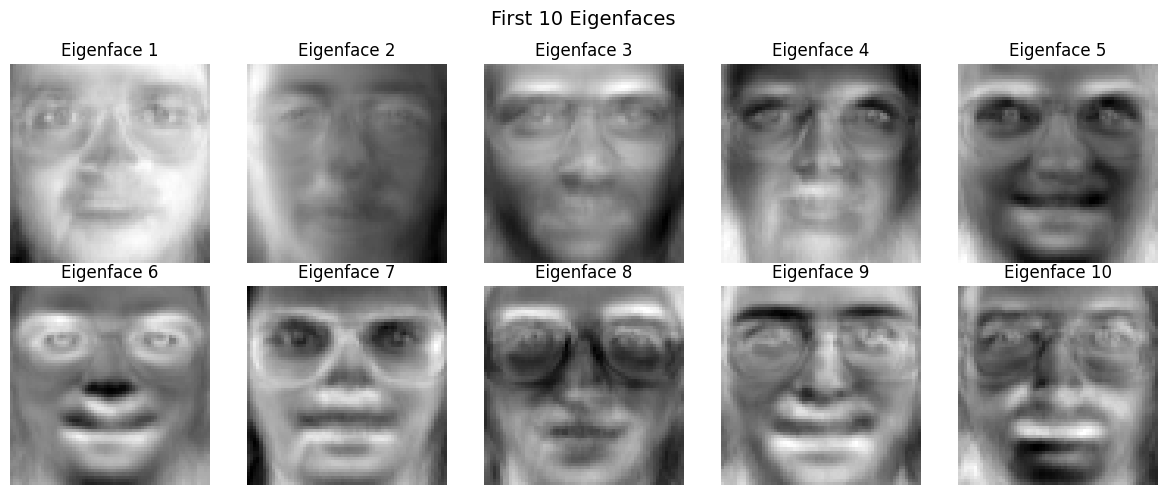

In [ ]:
# Eigenfaces principali --> colonne di U
eigenfaces = U # ogni colonna è un eigenface
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    eigenface = U[:, i].reshape(64, 64)
    ax.imshow(eigenface, cmap='gray')
    ax.set_title(f"Eigenface {i+1}")
    ax.axis('off')

plt.suptitle("First 10 Eigenfaces", fontsize=14)
plt.tight_layout()
plt.show()

# How many eigenfaces do we need?
It can be observed that with **slightly more than 50 eigenfaces it is possible to explain nearly 90% of the total variance of the dataset**. Indeed, using this reduced dimensionality yields classification performance comparable to that obtained when retaining all 4096 pixel features. However, since the data are represented in a significantly lower-dimensional subspace, the computational cost is substantially reduced.

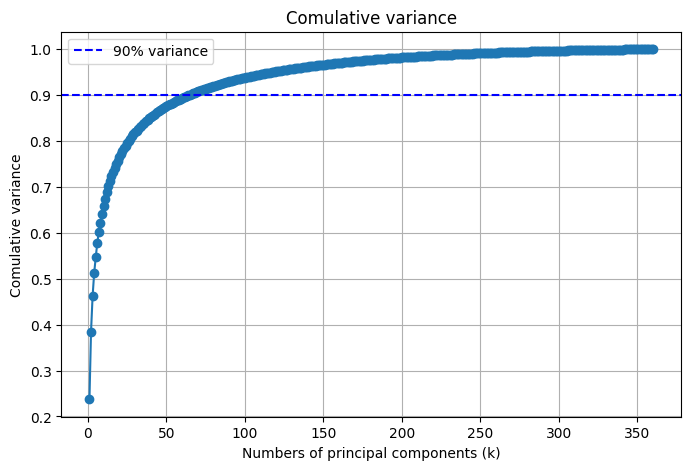

In [ ]:
# lambdas: array degli autovalori già calcolati (in ordine decrescente)
var_total = np.sum(lambdas)
var_cum = np.cumsum(lambdas) / var_total  # varianza cumulativa normalizzata [0,1]

# Grafico
plt.figure(figsize=(8,5))
plt.plot(np.arange(1, len(lambdas)+1), var_cum, marker='o', linestyle='-')
plt.xlabel('Numbers of principal components (k)')
plt.ylabel('Comulative variance')
plt.title('Comulative variance')
plt.grid(True)
plt.axhline(y=0.9, color='b', linestyle='--', label='90% variance')
plt.legend()
plt.show()

In [ ]:
k = 50
top_lambdas = lambdas[:k]
Vk_T = eigenfaces[:k, :]

#cambio base per il train
Qk_T=Vk_T@(S_bar).T
Qk=Qk_T.T

#cambio base per il test ricentrato
X_test_centred=X_test-mean_pixels
Yk_T=Vk_T@(X_test_centred).T
Yk=Yk_T.T

#predico chi è il più vicino
kn=KNeighborsClassifier(n_neighbors=1)
kn.fit(Qk,y_train)
y_pred=kn.predict(Yk)
acc=np.array([y_pred==y_test]).sum()/len(y_test)
print('Accuracy: ', acc)
print('Number of wrong associations: ', np.array([y_pred!=y_test]).sum())

Accuracy:  0.95
Number of wrong associations:  2


In [ ]:
y_pred

array([15,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 25, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
       34, 35, 36, 37, 38, 39], dtype=int32)

The same misclassification observed previously occurred again, with subject 22 being incorrectly identified as subject 25. This error arises both when using the full dataset and when employing PCA, likely because correctly matching this specific test image is particularly challenging.

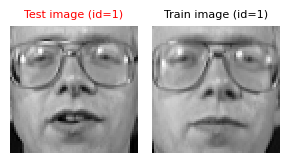

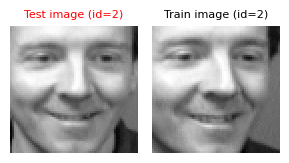

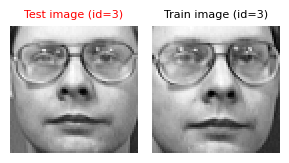

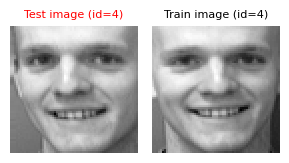

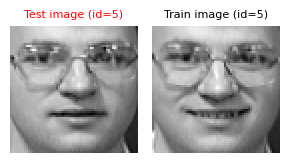

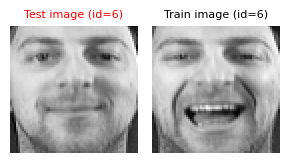

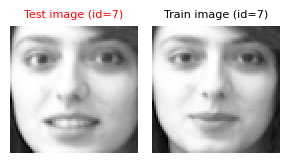

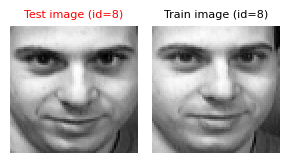

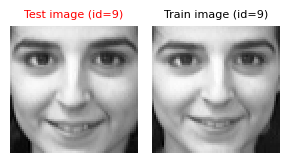

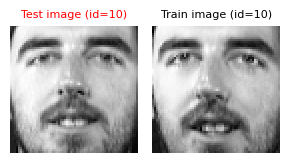

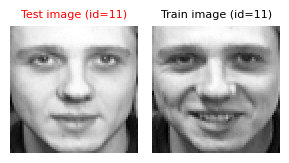

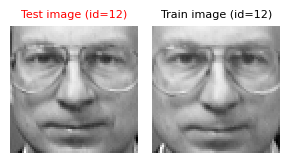

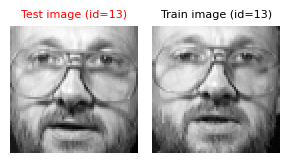

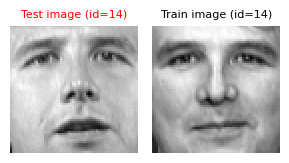

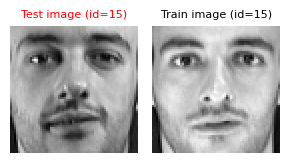

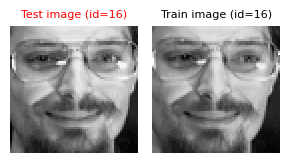

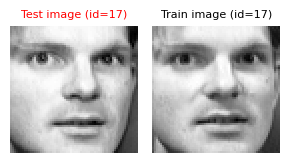

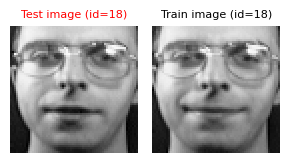

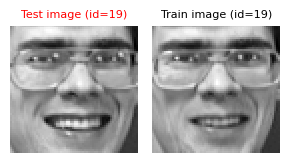

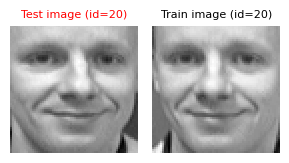

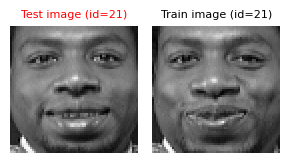

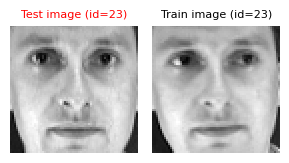

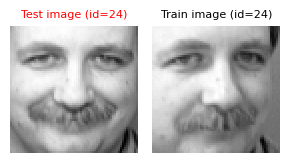

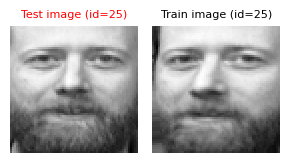

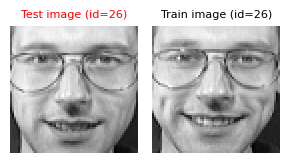

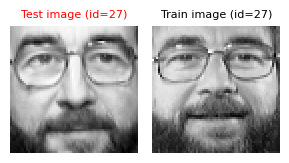

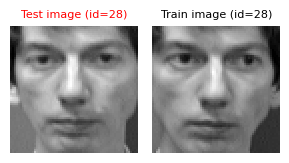

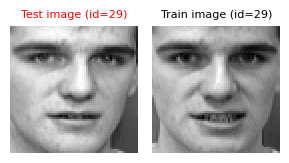

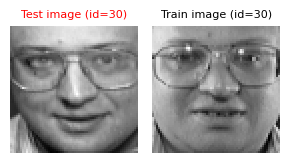

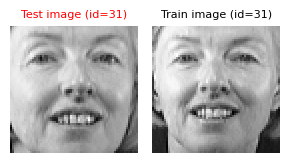

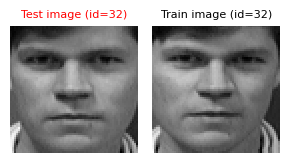

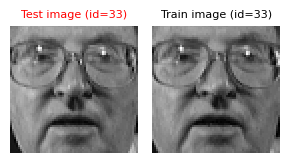

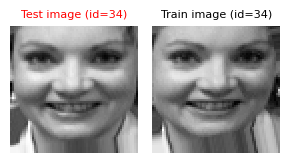

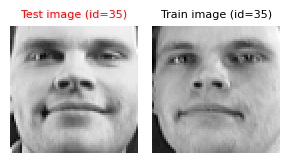

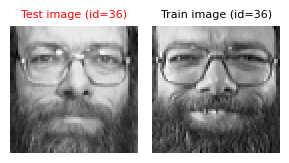

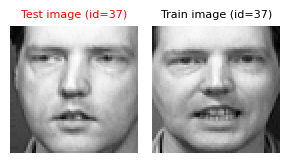

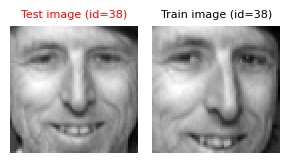

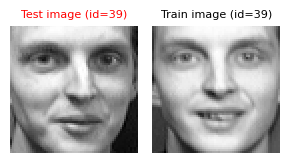

In [ ]:
correct_idx = np.where(y_test == y_pred)[0]
for i in correct_idx:
    fig, axes = plt.subplots(1, 2, figsize=(3, 3))

    # --- test image ---
    img_test = X_test.iloc[i, :].to_numpy().reshape(64, 64)
    label = y_test[i]

    axes[0].imshow(img_test, cmap='gray')
    axes[0].set_title(f"Test image (id={label})",fontsize=8,color='red')
    axes[0].axis('off')

    # --- corresponding train image ---
    idx_train = np.where(y_train == label)[0]
    j = idx_train[0]   # ne prendiamo una a caso (la prima)

    img_train = X_train.iloc[j, :].to_numpy().reshape(64, 64)

    axes[1].imshow(img_train, cmap='gray')
    axes[1].set_title(f"Train image (id={label})",fontsize=8)
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

Image that was wrongly predicted

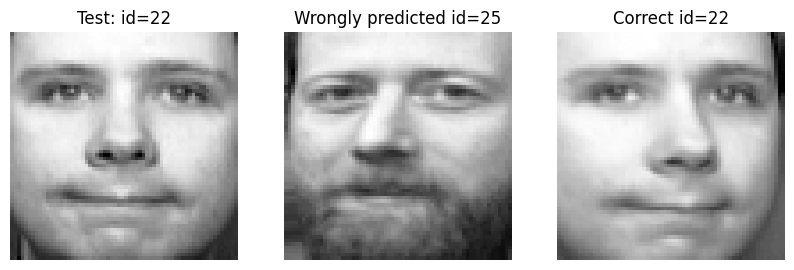

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
# immagine 22 di X_test -> la foto da classificare che si è sbagiato
img22 = X_test.iloc[22,:].to_numpy().reshape(64, 64)
axes[0].imshow(img22, cmap='gray')
axes[0].set_title("Test: id=22")
axes[0].axis('off')
# indici delle immagini di subject 25 nel train
idx_22_train = np.where(y_train == 25)[0]
# prendiamo, ad esempio, la prima
i = idx_22_train[0]
img22_train = np.array(X_train.iloc[i,:]).reshape(64, 64)
axes[1].imshow(img22_train, cmap='gray')
axes[1].set_title("Wrongly predicted id=25")
axes[1].axis('off')
# indici delle immagini di subject 22 nel train
idx_22_train = np.where(y_train == 22)[0]
# prendiamo, ad esempio, la prima
i = idx_22_train[0]
img22_train = np.array(X_train.iloc[i,:]).reshape(64, 64)
axes[2].imshow(img22_train, cmap='gray')
axes[2].set_title("Correct id=22")
axes[2].axis('off')
plt.show()

# How can we achieve the same result of the mean method using very small numbers of eigenfaces?
It can be observed that the **same classification accuracy** achieved by the **mean-based method**(2) can be obtained using **only 7 eigenfaces**, corresponding to a very low-dimensional subspace. In this case, the number of misclassifications is four, which is identical to that observed for the mean-based approach.

In [ ]:
k = 7
top_lambdas = lambdas[:k]
Vk_T = eigenfaces[:k, :]

#cambio base per il train
Qk_T=Vk_T@(S_bar).T
Qk=Qk_T.T

#cambio base per il test ricentrato
X_test_centred=X_test-mean_pixels
Yk_T=Vk_T@(X_test_centred).T
Yk=Yk_T.T

#predico chi è il più vicino
#costo computazionale 10 features per 360 foto
kn=KNeighborsClassifier(n_neighbors=1)
kn.fit(Qk,y_train)
y_pred=kn.predict(Yk)
acc=np.array([y_pred==y_test]).sum()/len(y_test)
print('Accuracy: ', acc)
print('Number of wrong associations: ', np.array([y_pred!=y_test]).sum())

Accuracy:  0.9
Number of wrong associations:  4


In [ ]:
print(y_pred)

[ 9  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 30 21  3 23
 24 25 26 27 28 29 30 31 29 33 34 35 36 37 38 39]


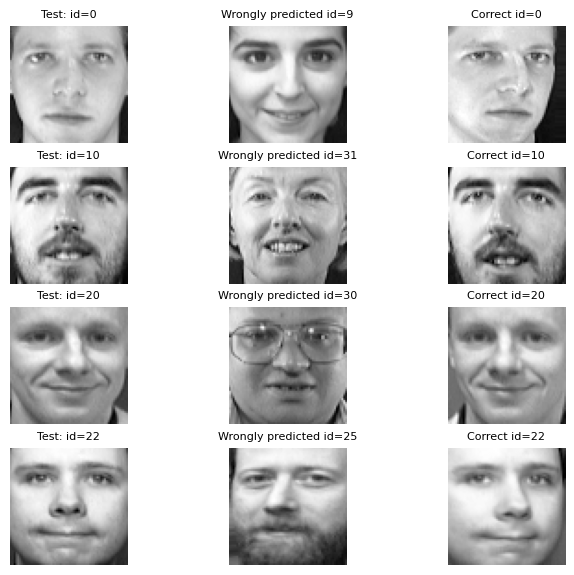

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(8, 7))
axes = axes.flatten()

img22 = X_test.iloc[0,:].to_numpy().reshape(64, 64)
axes[0].imshow(img22, cmap='gray')
axes[0].set_title("Test: id=0",fontsize=8)
axes[0].axis('off')
idx_22_train = np.where(y_train == 9)[0]
i = idx_22_train[0]
img22_train = np.array(X_train.iloc[i,:]).reshape(64, 64)
axes[1].imshow(img22_train, cmap='gray')
axes[1].set_title("Wrongly predicted id=9",fontsize=8)
axes[1].axis('off')
idx_22_train = np.where(y_train == 0)[0]
i = idx_22_train[0]
img22_train = np.array(X_train.iloc[i,:]).reshape(64, 64)
axes[2].imshow(img22_train, cmap='gray')
axes[2].set_title("Correct id=0",fontsize=8)
axes[2].axis('off')
###################################################
img22 = X_test.iloc[10,:].to_numpy().reshape(64, 64)
axes[3].imshow(img22, cmap='gray')
axes[3].set_title("Test: id=10",fontsize=8)
axes[3].axis('off')
idx_22_train = np.where(y_train == 31)[0]
i = idx_22_train[0]
img22_train = np.array(X_train.iloc[i,:]).reshape(64, 64)
axes[4].imshow(img22_train, cmap='gray')
axes[4].set_title("Wrongly predicted id=31",fontsize=8)
axes[4].axis('off')
idx_22_train = np.where(y_train == 10)[0]
i = idx_22_train[0]
img22_train = np.array(X_train.iloc[i,:]).reshape(64, 64)
axes[5].imshow(img22_train, cmap='gray')
axes[5].set_title("Correct id=10",fontsize=8)
axes[5].axis('off')
#########################
img22 = X_test.iloc[20,:].to_numpy().reshape(64, 64)
axes[6].imshow(img22, cmap='gray')
axes[6].set_title("Test: id=20",fontsize=8)
axes[6].axis('off')
idx_22_train = np.where(y_train == 30)[0]
i = idx_22_train[0]
img22_train = np.array(X_train.iloc[i,:]).reshape(64, 64)
axes[7].imshow(img22_train, cmap='gray')
axes[7].set_title("Wrongly predicted id=30",fontsize=8)
axes[7].axis('off')
idx_22_train = np.where(y_train == 20)[0]
i = idx_22_train[0]
img22_train = np.array(X_train.iloc[i,:]).reshape(64, 64)
axes[8].imshow(img22_train, cmap='gray')
axes[8].set_title("Correct id=20",fontsize=8)
axes[8].axis('off')
###################################
img22 = X_test.iloc[22,:].to_numpy().reshape(64, 64)
axes[9].imshow(img22, cmap='gray')
axes[9].set_title("Test: id=22",fontsize=8)
axes[9].axis('off')
idx_22_train = np.where(y_train == 25)[0]
i = idx_22_train[0]
img22_train = np.array(X_train.iloc[i,:]).reshape(64, 64)
axes[10].imshow(img22_train, cmap='gray')
axes[10].set_title("Wrongly predicted id=25",fontsize=8)
axes[10].axis('off')
idx_22_train = np.where(y_train == 22)[0]
i = idx_22_train[0]
img22_train = np.array(X_train.iloc[i,:]).reshape(64, 64)
axes[11].imshow(img22_train, cmap='gray')
axes[11].set_title("Correct id=22",fontsize=8)
axes[11].axis('off')
plt.show()

# **Conclusion**

In this study, we implemented and compared three facial recognition approaches: the naive method, the mean-based method, and the PCA-based method.

These results highlight the following points:
1) The naive method achieves the hi**ghest accuracy** but at a h**igh computational cost**.
2) The mean-based method reduces computational cost but s**acrifices accuracy**.
3)  PCA provides a flexible trade-off: with $k = 50$ components, it retains the **accuracy of the naive method at much lower cost**, and with $k = 7$ components, it achieves the same accuracy as the m**ean-based method while drastically reducing feature dimensionality** **testo in grassetto** and computational burden.

Overall, dimensionality reduction via PCA proves to be an effective strategy for maintaining high recognition performance while substantially decreasing both computational and memory requirements.

In [ ]:
from google.colab import files
from IPython.display import Image
uploaded = files.upload()

Saving foto6.png to foto6.png


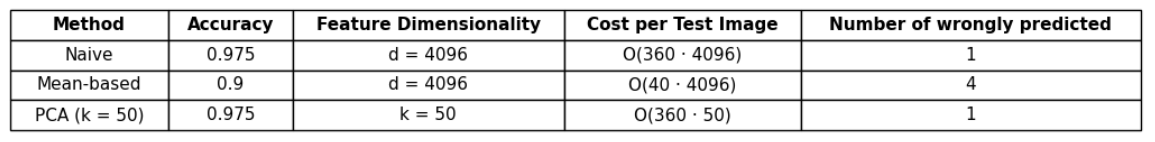

In [ ]:
Image('foto6.png')